## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [458]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

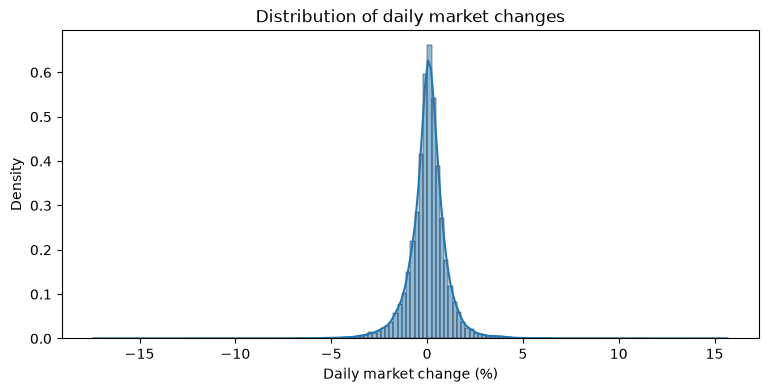

In [459]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

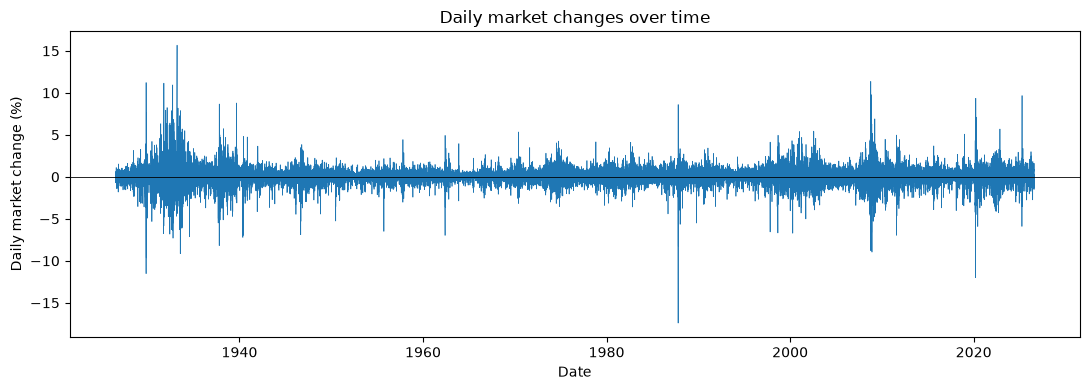

In [460]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [461]:
df['market_return_pct'].describe()

count    26296.000000
mean         0.043005
std          1.077241
min        -17.410000
25%         -0.390000
50%          0.080000
75%          0.510000
max         15.670000
Name: market_return_pct, dtype: float64

In [462]:
df['mkt_return_gtr0'] = (df['market_return_pct'] > 0)

df['y_t'] = df['mkt_return_gtr0'].map({False:'Down', True:'Up'})
df['y_tp1'] = df['mkt_return_gtr0'].shift(-1).map({False:'Down', True:'Up'}) # Shift into the future

#JOINT PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
tab

y_tp1,Down,Up
y_t,,
Down,0.224720,0.228142
Up,0.228142,0.318996


In [463]:
#MARGINALS
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = True, margins = True)
tab

y_tp1,Down,Up,All
y_t,,,
Down,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [464]:
#CONDITIONAL PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab

y_tp1,Down,Up
y_t,,
Down,0.496221,0.503779
Up,0.416974,0.583026


- equally common?
- most likely to transition to an up day from an up day

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [465]:
df['market_return_pct'].describe()

count    26296.000000
mean         0.043005
std          1.077241
min        -17.410000
25%         -0.390000
50%          0.080000
75%          0.510000
max         15.670000
Name: market_return_pct, dtype: float64

In [466]:
df['market_return_pct'].sort_values(ascending=True)

16527   -17.41
24693   -12.00
992     -11.53
991     -11.23
996      -9.64
         ...  
1853     10.94
1565     11.15
993      11.22
21819    11.36
1986     15.67
Name: market_return_pct, Length: 26296, dtype: float64

In [467]:
df['mkt_return_bin'] = pd.cut(
    df['market_return_pct'],
    bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf],
    labels=['Large Loss', 'Small Loss', 'Near Zero', 'Small Gain', 'Extreme Gain']
)
df['y_t'] = df['mkt_return_bin']
df['y_tp1'] = df['mkt_return_bin'].shift(-1)

In [468]:
#Number of days in each bin
df['mkt_return_bin'].value_counts().sort_values()

mkt_return_bin
Large Loss      2759
Extreme Gain    2859
Near Zero       3441
Small Loss      7452
Small Gain      9785
Name: count, dtype: int64

#### How many days fall into each of the five bins? Which are the most or least common?:
The above code outputs the number of days that fall into each of the bins. The most common is 'Small Gain' at 9,785 days and the least common is 'Large Loss' at 2,759 days. It appears that 'Small Loss' and 'Small Gain' have a noticeably higher number of days compared to 'Large Loss' and 'Extreme Gain'.

In [469]:
#JOINT PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize=True)
tab

y_tp1,Large Loss,Small Loss,Near Zero,Small Gain,Extreme Gain
y_t,,,,,
Large Loss,0.021335,0.027191,0.009051,0.027800,0.019547
Small Loss,0.035444,0.088648,0.034151,0.097775,0.027382
Near Zero,0.009317,0.041985,0.020955,0.049325,0.009279
Small Gain,0.024986,0.100057,0.055029,0.159422,0.032592
Extreme Gain,0.013843,0.025518,0.011637,0.037802,0.019928


[Text(0.5, 1.0, 'Joint PMF')]

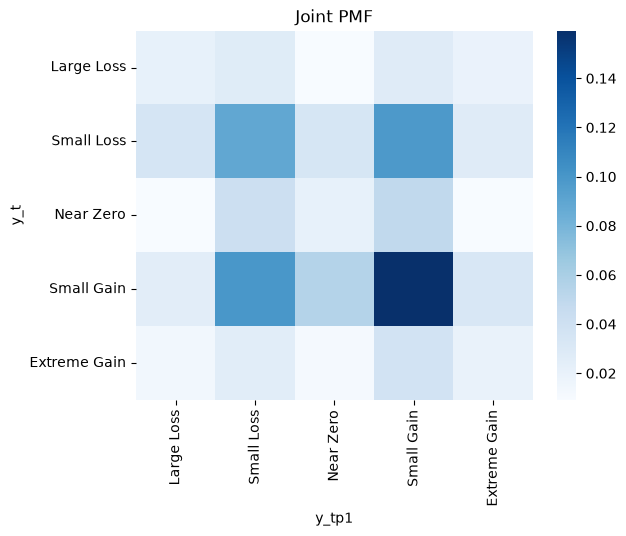

In [470]:
sns.heatmap(tab, fmt='.2f', cmap='Blues').set(title='Joint PMF')

#### Which transitions are most likely to occur?
It appears that the most common transitions are from 'Small Loss' to either 'Small Loss' and 'Small Gain', and from 'Small Gain' to either 'Small Gain' or 'Small Loss'. This means that small losses and gains today most often occur with small losses or gains tomorrow. It is important to note though that 'Large Loss' and 'Extreme Gain' are less frequent which will impact the joint probability.

For really bad today appears to have an equal proportion of really bad tomorrow and really good tomorrow.

In [471]:
#CONDITIONAL PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab

y_tp1,Large Loss,Small Loss,Near Zero,Small Gain,Extreme Gain
y_t,,,,,
Large Loss,0.203335,0.259152,0.086263,0.264951,0.186299
Small Loss,0.125067,0.312802,0.120505,0.345008,0.096618
Near Zero,0.071200,0.320837,0.160128,0.376925,0.070910
Small Gain,0.067150,0.268908,0.147895,0.428455,0.087592
Extreme Gain,0.127317,0.234697,0.107030,0.347674,0.183281


[Text(0.5, 1.0, 'Conditional PMF')]

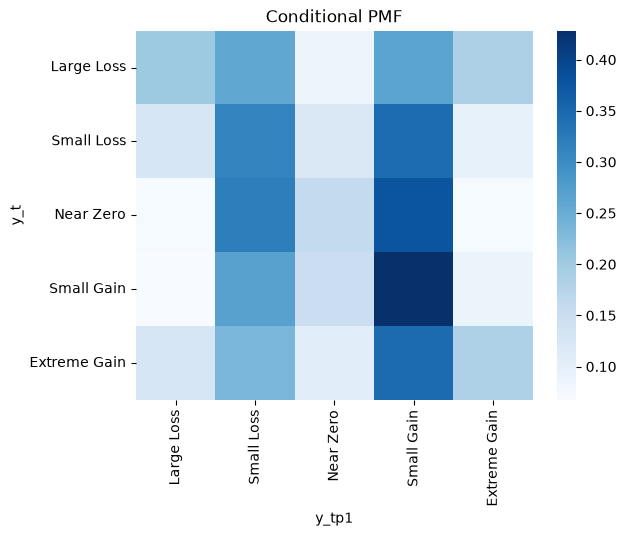

In [472]:
sns.heatmap(tab, fmt='.2f', cmap='Blues').set(title='Conditional PMF')

#### For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

Most likely future states for each current state:
- Large Loss: Small Loss and Small Gain
- Small Loss: Small Gain and Small Loss
- Near Zero: Small Gain and Small Loss
- Extreme Gain: Small Gain and Small Loss

**These do center around .2 and are within .1-.2 of it????** Because these all have similar probabilities over each transition it is difficult to predict the next state as for any state today there is a fairly equal likelihood of getting any other state next.



In [473]:
df['mkt_return_tp1'] = df['market_return_pct'].shift(-1)
grouped_df = df.groupby('mkt_return_bin').agg(
    mkt_return_tp1_min = ('mkt_return_tp1', 'min'),
    mkt_return_tp1_mean = ('mkt_return_tp1', 'mean'),
    mkt_return_tp1_max = ('mkt_return_tp1', 'max'),
    mkt_return_tp1_std = ('mkt_return_tp1', 'std')
)

grouped_df.sort_values(by='mkt_return_tp1_std')

/var/folders/rf/v6lnf4j94_j1gq143nx7p8f80000gn/T/ipykernel_40790/1408275772.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grouped_df = df.groupby('mkt_return_bin').agg(


,mkt_return_tp1_min,mkt_return_tp1_mean,mkt_return_tp1_max,mkt_return_tp1_std
mkt_return_bin,,,,
Near Zero,-8.19,0.015013,5.49,0.826054
Small Gain,-8.25,0.106810,8.67,0.832186
Small Loss,-11.23,-0.043814,11.36,1.009529
Extreme Gain,-12.00,0.163092,15.67,1.384086
Large Loss,-17.41,-0.038311,11.22,1.720570


#### For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice.

Did I do this right?

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [474]:
df['mkt_return_bin'] = pd.qcut(df['market_return_pct'], q=21, labels=False)

df['y_t'] = df['mkt_return_bin']
df['y_tp1'] = df['mkt_return_bin'].shift(-1)

In [475]:
#JOINT PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'],
            normalize=True)
tab_sub = tab - 1/21**2
tab_sub

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.004692,0.001383,0.000661,-0.000480,-0.000062,-0.000518,-0.000442,-0.001127,-0.000898,-0.000937,...,-0.001241,-0.000937,-0.000937,-0.001165,-0.000670,-0.001127,-0.000328,-0.000252,0.001345,0.004616
1,0.002600,0.001117,0.000927,-0.000062,0.000052,-0.000290,-0.000062,-0.000594,-0.000822,0.000052,...,-0.000708,-0.000937,-0.000746,-0.000556,-0.000670,-0.000442,-0.000442,0.000623,0.000242,0.001383
2,0.001383,0.001497,0.001459,0.001535,-0.000024,-0.000404,-0.000138,-0.000442,-0.000784,-0.000214,...,-0.000290,0.000090,-0.000024,-0.000632,-0.000898,-0.000214,-0.000442,0.000052,0.000242,0.000395
3,0.000547,0.001421,0.000813,0.000509,0.000433,0.000204,0.000090,-0.000708,-0.000138,0.000128,...,-0.000480,-0.000328,-0.000746,0.000014,-0.000138,0.000014,-0.000480,0.000166,0.000280,-0.000176
4,0.000052,0.000433,0.000623,0.000318,-0.000138,0.000280,0.000356,-0.000100,0.000052,-0.000442,...,-0.000214,-0.000404,-0.000518,0.000471,-0.000100,-0.000328,0.000395,-0.000632,0.000014,-0.000404
5,-0.000214,0.000585,0.000242,0.000623,0.000471,-0.000062,0.000014,0.000166,-0.000328,-0.000138,...,-0.000404,-0.000062,-0.000176,-0.000328,-0.000214,0.000318,0.000356,-0.000708,-0.000328,-0.000328
6,0.000128,0.000547,0.001079,0.000927,0.000547,0.000547,-0.000062,-0.000024,0.000166,0.000204,...,-0.000328,0.000318,0.000927,0.000242,-0.000138,0.000242,-0.000328,-0.000518,0.000128,-0.000594
7,-0.000746,0.000090,0.000166,0.000889,-0.000100,0.000090,0.000509,0.000166,-0.000366,0.000014,...,0.000090,0.000204,-0.000404,-0.000062,-0.000062,-0.000746,-0.000328,-0.000404,-0.000290,-0.001089
8,-0.000937,-0.000252,0.000166,0.000166,0.000242,0.000204,0.000052,0.000204,0.000090,0.000471,...,0.000204,0.000166,-0.000062,0.000242,0.000090,-0.000366,-0.000138,-0.000480,-0.000822,-0.000746


[Text(0.5, 1.0, 'Joint PMF')]

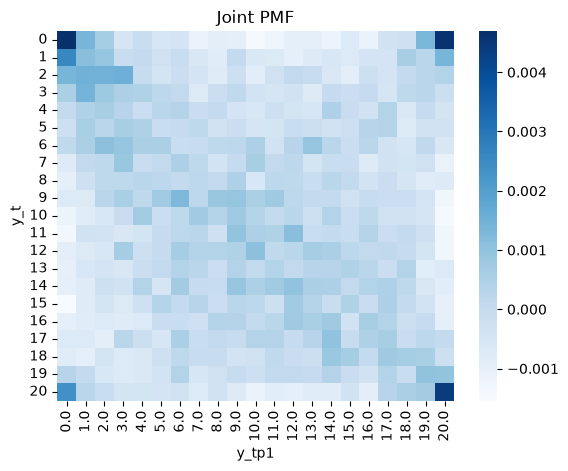

In [476]:
sns.heatmap(tab_sub, fmt='.2f', cmap='Blues').set(title='Joint PMF')

In [477]:
#CONDITIONAL PMF
tab = pd.crosstab(df['y_t'], df['y_tp1'], 
            normalize = 'index')
tab_sub = tab - 1/21
tab_sub

y_tp1,0.0,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,...,11.0,12.0,13.0,14.0,15.0,16.0,17.0,18.0,19.0,20.0
y_t,,,,,,,,,,,,,,,,,,,,,
0,0.098198,0.028875,0.013736,-0.010169,-0.001404,-0.010966,-0.009372,-0.023715,-0.018934,-0.019731,...,-0.026105,-0.019731,-0.019731,-0.024511,-0.014153,-0.023715,-0.006982,-0.005388,0.028078,0.096604
1,0.054536,0.023410,0.019420,-0.001330,0.001064,-0.006119,-0.001330,-0.012503,-0.017292,0.001064,...,-0.014898,-0.019686,-0.015696,-0.011705,-0.014099,-0.009311,-0.009311,0.013035,0.005055,0.028997
2,0.027031,0.029364,0.028586,0.030141,-0.001740,-0.009516,-0.004073,-0.010294,-0.017292,-0.005628,...,-0.007184,0.000592,-0.001740,-0.014182,-0.019625,-0.005628,-0.010294,-0.000185,0.003703,0.006813
3,0.010193,0.028162,0.015662,0.009412,0.007850,0.003162,0.000818,-0.015588,-0.003869,0.001600,...,-0.010900,-0.007775,-0.016369,-0.000744,-0.003869,-0.000744,-0.010900,0.002381,0.004725,-0.004650
4,0.001974,0.010105,0.014170,0.007666,-0.002091,0.006852,0.008479,-0.001278,0.001974,-0.008595,...,-0.003717,-0.007782,-0.010221,0.010918,-0.001278,-0.006156,0.009292,-0.012660,0.001161,-0.007782
5,-0.003573,0.013556,0.006215,0.014371,0.011109,-0.000311,0.001321,0.004583,-0.006020,-0.001942,...,-0.007652,-0.000311,-0.002758,-0.006020,-0.003573,0.007846,0.008662,-0.014177,-0.006020,-0.006020
6,-0.001667,0.006356,0.016568,0.013650,0.006356,0.006356,-0.005314,-0.004585,-0.000938,-0.000208,...,-0.010420,0.001980,0.013650,0.000521,-0.006773,0.000521,-0.010420,-0.014067,-0.001667,-0.015526
7,-0.014452,0.003791,0.005449,0.021204,-0.000355,0.003791,0.012912,0.005449,-0.006160,0.002132,...,0.003791,0.006278,-0.006989,0.000474,0.000474,-0.014452,-0.005330,-0.006989,-0.004501,-0.021914
8,-0.018404,-0.003379,0.005803,0.005803,0.007473,0.006638,0.003299,0.006638,0.004134,0.012481,...,0.006638,0.005803,0.000795,0.007473,0.004134,-0.005883,-0.000874,-0.008387,-0.015900,-0.014230


[Text(0.5, 1.0, 'Joint PMF')]

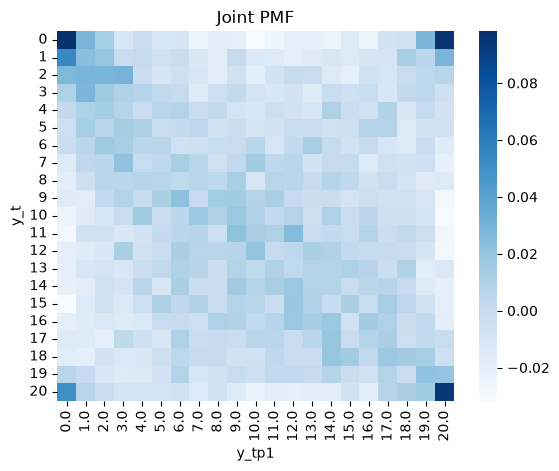

In [478]:
sns.heatmap(tab_sub, fmt='.2f', cmap='Blues').set(title='Joint PMF')

In [479]:
df['mkt_return_tp1'] = df['market_return_pct'].shift(-1)
grouped_df = df.groupby('y_t').agg(
    mkt_return_tp1_min = ('mkt_return_tp1', 'min'),
    mkt_return_tp1_mean = ('mkt_return_tp1', 'mean'),
    mkt_return_tp1_max = ('mkt_return_tp1', 'max')
)

Text(0, 0.5, 'Next Day Market Return Percentage')

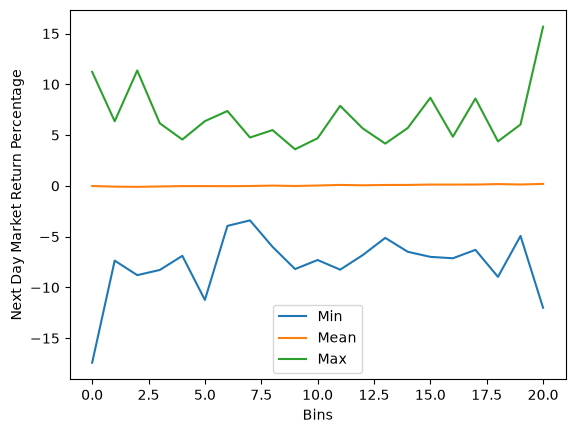

In [480]:
import matplotlib.pyplot as plt

plt.plot(grouped_df.index, grouped_df['mkt_return_tp1_min'], label='Min')
plt.plot(grouped_df.index, grouped_df['mkt_return_tp1_mean'], label='Mean')
plt.plot(grouped_df.index, grouped_df['mkt_return_tp1_max'], label='Max')
plt.legend()
plt.xlabel('Bins')
plt.ylabel("Next Day Market Return Percentage")

In [481]:
std_df = df.groupby('y_t').agg(mkt_return_tp1_std = ('mkt_return_tp1', 'std'))
std_df

,mkt_return_tp1_std
y_t,
0,2.140465
1,1.285882
2,1.227976
3,1.049607
4,0.989470
5,1.024761
6,0.930389
7,0.835663
8,0.853220


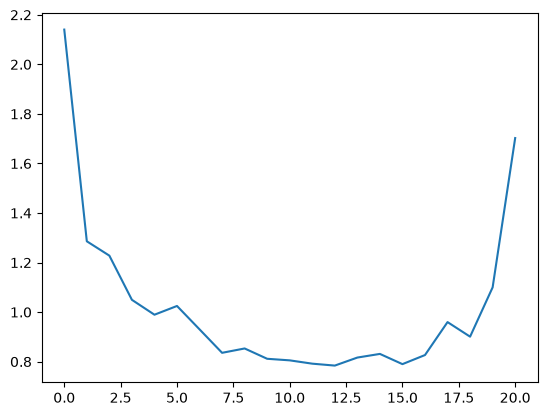

In [482]:
plt.plot(grouped_df.index, std_df['mkt_return_tp1_std'], label='Standard Deviation')

Large values are more variable (higher standard deviations) more chance to make money but also more chance to lose a lot of money.